<a href="https://colab.research.google.com/github/manojss14/ML2_MANOJSS_4NI22CI034/blob/main/ML2_exp08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install minisom -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

print("Libraries imported successfully!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Libraries imported successfully!


In [2]:
data = {
    'Customer_ID': range(1, 21),

    'Annual_Income': [
        15, 16, 17, 18, 20,
        25, 28, 30, 35, 40,
        45, 50, 55, 60, 65,
        70, 75, 80, 85, 90
    ],

    'Spending_Score': [
        80, 85, 78, 90, 75,
        70, 65, 60, 55, 50,
        45, 40, 35, 30, 25,
        20, 15, 25, 10, 5
    ]
}

df = pd.DataFrame(data)

# Save dataset as CSV
df.to_csv('customer_data.csv', index=False)

print("Dataset created successfully!")

display(df.head(20))

Dataset created successfully!


,Customer_ID,Annual_Income,Spending_Score
0,1,15,80
1,2,16,85
2,3,17,78
3,4,18,90
4,5,20,75
5,6,25,70
6,7,28,65
7,8,30,60
8,9,35,55
9,10,40,50


In [3]:
df = pd.read_csv('customer_data.csv')

print("Dataset loaded successfully!")

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nDataset shape:")
print(df.shape)

Dataset loaded successfully!

First five records:


,Customer_ID,Annual_Income,Spending_Score
0,1,15,80
1,2,16,85
2,3,17,78
3,4,18,90
4,5,20,75



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Customer_ID     20 non-null     int64
 1   Annual_Income   20 non-null     int64
 2   Spending_Score  20 non-null     int64
dtypes: int64(3)
memory usage: 612.0 bytes

Dataset shape:
(20, 3)


In [4]:
# Select input features
X = df[['Annual_Income', 'Spending_Score']].values

# Normalize data between 0 and 1
scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)

print("Normalized Data:")
print(X_scaled)

Normalized Data:
[[0.         0.88235294]
 [0.01333333 0.94117647]
 [0.02666667 0.85882353]
 [0.04       1.        ]
 [0.06666667 0.82352941]
 [0.13333333 0.76470588]
 [0.17333333 0.70588235]
 [0.2        0.64705882]
 [0.26666667 0.58823529]
 [0.33333333 0.52941176]
 [0.4        0.47058824]
 [0.46666667 0.41176471]
 [0.53333333 0.35294118]
 [0.6        0.29411765]
 [0.66666667 0.23529412]
 [0.73333333 0.17647059]
 [0.8        0.11764706]
 [0.86666667 0.23529412]
 [0.93333333 0.05882353]
 [1.         0.        ]]


In [5]:
# Initialize SOM

som = MiniSom(
    x=5,
    y=5,
    input_len=2,
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize weights
som.random_weights_init(X_scaled)

print("SOM model initialized successfully!")

SOM model initialized successfully!


In [6]:
# Train SOM
som.train_random(
    X_scaled,
    num_iteration=1000
)

print("SOM training completed successfully!")

SOM training completed successfully!


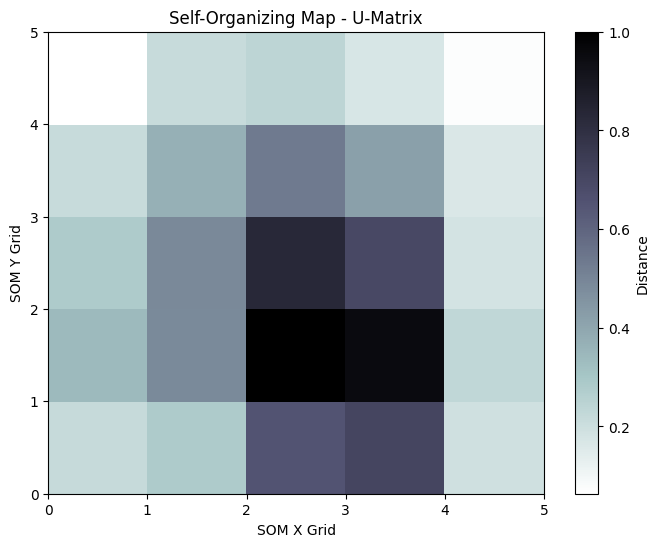

In [7]:
plt.figure(figsize=(8, 6))

plt.pcolor(
    som.distance_map().T,
    cmap='bone_r'
)

plt.colorbar(label='Distance')

plt.title("Self-Organizing Map - U-Matrix")

plt.xlabel("SOM X Grid")
plt.ylabel("SOM Y Grid")

plt.show()

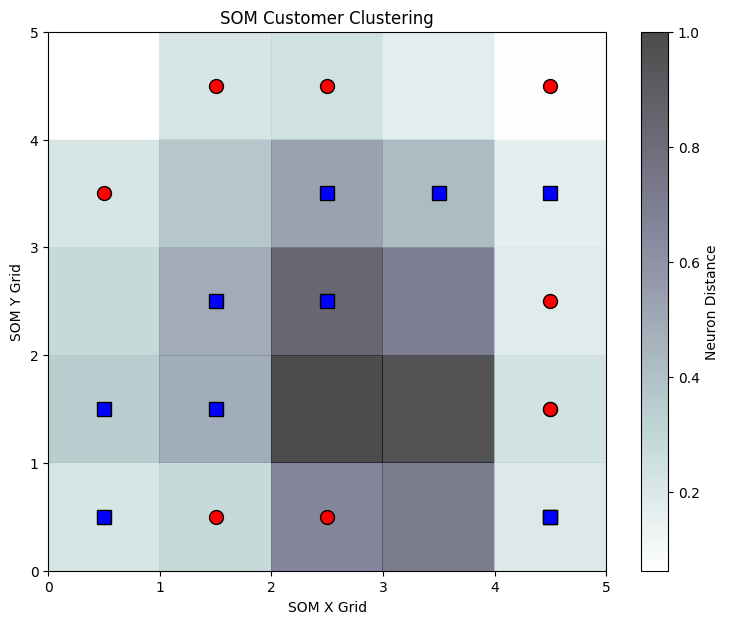

In [8]:
plt.figure(figsize=(9, 7))

# Plot SOM distance map
plt.pcolor(
    som.distance_map().T,
    cmap='bone_r',
    alpha=0.7
)

plt.colorbar(label='Neuron Distance')

# Plot customer data
markers = ['o', 's']
colors = ['red', 'blue']

for i, x in enumerate(X_scaled):

    # Find Best Matching Unit
    w = som.winner(x)

    plt.plot(
        w[0] + 0.5,
        w[1] + 0.5,
        markers[i % 2],
        markerfacecolor=colors[i % 2],
        markeredgecolor='black',
        markersize=10
    )

plt.title("SOM Customer Clustering")

plt.xlabel("SOM X Grid")
plt.ylabel("SOM Y Grid")

plt.show()

In [9]:
# Find BMU for each customer

bmu_coordinates = []

for x in X_scaled:

    bmu = som.winner(x)

    bmu_coordinates.append(bmu)

# Add SOM coordinates to dataset

df['SOM_X'] = [bmu[0] for bmu in bmu_coordinates]
df['SOM_Y'] = [bmu[1] for bmu in bmu_coordinates]

print("Customer SOM Mapping:")

display(df)

Customer SOM Mapping:


,Customer_ID,Annual_Income,Spending_Score,SOM_X,SOM_Y
0,1,15,80,4,1
1,2,16,85,4,0
2,3,17,78,4,1
3,4,18,90,4,0
4,5,20,75,4,2
5,6,25,70,4,3
6,7,28,65,4,4
7,8,30,60,3,3
8,9,35,55,2,4
9,10,40,50,2,3


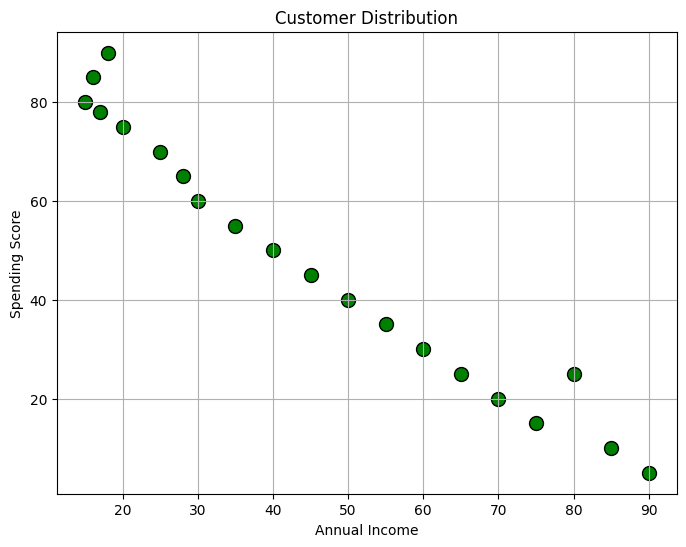

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df['Annual_Income'],
    df['Spending_Score'],
    color='green',
    s=100,
    edgecolor='black'
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.title("Customer Distribution")

plt.grid(True)

plt.show()

In [11]:
# Create SOM group labels
df['SOM_Group'] = (
    df['SOM_X'].astype(str) + "_" +
    df['SOM_Y'].astype(str)
)

print("Customer Groups:")

display(
    df[['Customer_ID', 'Annual_Income',
        'Spending_Score', 'SOM_Group']]
)

# Count customers in each group
print("\nNumber of Customers in Each SOM Group:")

print(df['SOM_Group'].value_counts())

Customer Groups:


,Customer_ID,Annual_Income,Spending_Score,SOM_Group
0,1,15,80,4_1
1,2,16,85,4_0
2,3,17,78,4_1
3,4,18,90,4_0
4,5,20,75,4_2
5,6,25,70,4_3
6,7,28,65,4_4
7,8,30,60,3_3
8,9,35,55,2_4
9,10,40,50,2_3



Number of Customers in Each SOM Group:
SOM_Group
4_1    2
4_0    2
0_0    2
4_3    1
4_2    1
3_3    1
2_4    1
2_3    1
4_4    1
1_4    1
2_2    1
1_2    1
0_3    1
2_0    1
1_1    1
1_0    1
0_1    1
Name: count, dtype: int64


In [12]:
# Save SOM results
df.to_csv('SOM_customer_results.csv', index=False)

print("SOM results saved successfully!")

from google.colab import files

files.download('SOM_customer_results.csv')

SOM results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>